In [48]:
import pandas as pd
df=pd.read_csv("student_performance_1000_rows.csv")

In [66]:
df.head(5)

,Hours_Studied,Attendance_Percent,Previous_Score,Assignments_Completed,Sleep_Hours,Performance_Score,Extracurricular_Activities_up
0,0,91,92,8,9.1,45,0
1,6,87,34,7,6.7,47,0
2,5,78,58,10,9.7,78,1
3,3,95,62,10,7.9,80,0
4,3,56,86,7,4.7,46,1


In [53]:
df.columns

Index(['Hours_Studied', 'Attendance_Percent', 'Previous_Score',
       'Assignments_Completed', 'Sleep_Hours', 'Extracurricular_Activities',
       'Performance_Score'],
      dtype='str')

In [54]:
import seaborn as sns

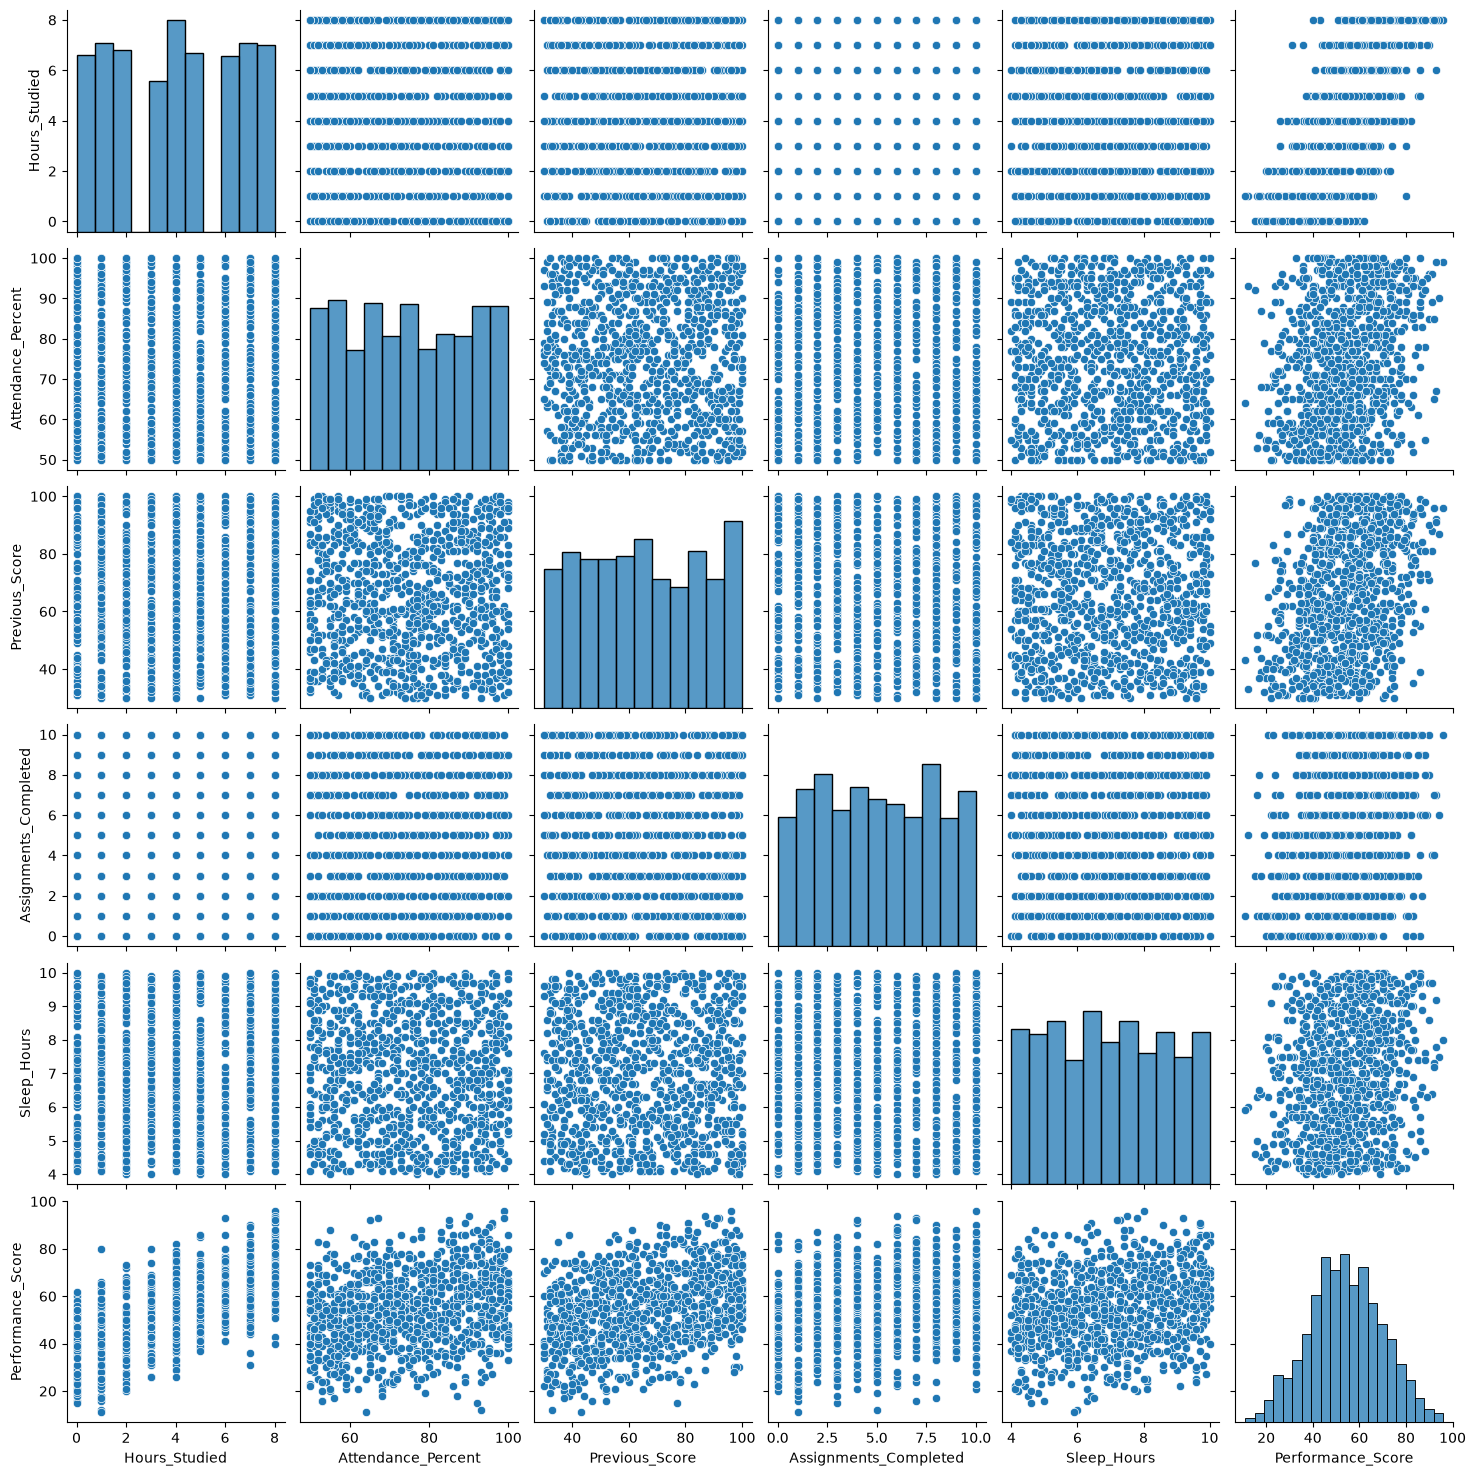

In [55]:
sns.pairplot(df)

In [57]:
df.isnull().sum()

Hours_Studied                 0
Attendance_Percent            0
Previous_Score                0
Assignments_Completed         0
Sleep_Hours                   0
Extracurricular_Activities    0
Performance_Score             0
dtype: int64

In [58]:
df.duplicated().sum()

np.int64(0)

In [60]:
print(df.head(5))

   Hours_Studied  Attendance_Percent  Previous_Score  Assignments_Completed  \
0              0                  91              92                      8   
1              6                  87              34                      7   
2              5                  78              58                     10   
3              3                  95              62                     10   
4              3                  56              86                      7   

   Sleep_Hours Extracurricular_Activities  Performance_Score  
0          9.1                         No                 45  
1          6.7                         No                 47  
2          9.7                        Yes                 78  
3          7.9                         No                 80  
4          4.7                        Yes                 46  


In [61]:
df.columns

Index(['Hours_Studied', 'Attendance_Percent', 'Previous_Score',
       'Assignments_Completed', 'Sleep_Hours', 'Extracurricular_Activities',
       'Performance_Score'],
      dtype='str')

In [62]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Hours_Studied               1000 non-null   int64  
 1   Attendance_Percent          1000 non-null   int64  
 2   Previous_Score              1000 non-null   int64  
 3   Assignments_Completed       1000 non-null   int64  
 4   Sleep_Hours                 1000 non-null   float64
 5   Extracurricular_Activities  1000 non-null   str    
 6   Performance_Score           1000 non-null   int64  
dtypes: float64(1), int64(5), str(1)
memory usage: 54.8 KB


In [63]:
def cond(val):
    if val=="Yes":
        return 1
    else:
        return 0


df["Extracurricular_Activities_up"]=df["Extracurricular_Activities"].apply(cond)

In [64]:
df.drop(columns=["Extracurricular_Activities"], inplace=True)

In [65]:
df.columns

Index(['Hours_Studied', 'Attendance_Percent', 'Previous_Score',
       'Assignments_Completed', 'Sleep_Hours', 'Performance_Score',
       'Extracurricular_Activities_up'],
      dtype='str')

In [67]:
x=df.drop(columns=["Performance_Score"])
y=df["Performance_Score"]

In [69]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0)

In [71]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import AdaBoostRegressor

In [72]:
models={
    "Multiple Linear Regression":LinearRegression(),
    "Multiple Ridge Regression":Ridge(alpha=0.5),
    "Multiple Lasso Regression":Lasso(alpha=0.5),
    "Multiple Elastic Net Regression":ElasticNet(l1_ratio=0.5),
    "Decision Tree Regression":DecisionTreeRegressor(),
    "Random Forest Regression":RandomForestRegressor(),
    "AdaBoost Regression":AdaBoostRegressor(),

}

In [77]:
from sklearn.metrics import r2_score
best_score=0
best_model=None
for name,model in models.items():
    model.fit(x_train,y_train)
    pred=model.predict(x_test)
    score=r2_score(y_test,pred)
    if score>best_score:
        best_score=score
        best_model=model
print(best_model)


Ridge(alpha=0.5)


In [78]:
import pickle
with open("model.pkl","wb") as file:
    pickle.dump(best_model,file)

In [79]:
print(type(best_model))

<class 'sklearn.linear_model._ridge.Ridge'>
